# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

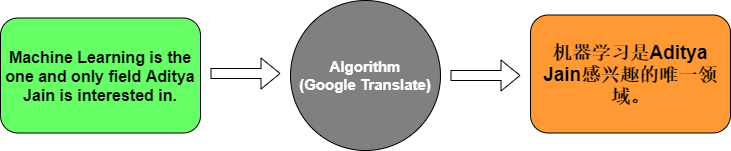

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [ ]:
#!pip install tensorflow

In [15]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [ ]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [ ]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [ ]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.1429 - loss: 2.4846 - val_accuracy: 0.0000e+00 - val_loss: 2.4882
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step - accuracy: 0.5714 - loss: 2.4762 - val_accuracy: 0.0000e+00 - val_loss: 2.4898
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.5714 - loss: 2.4675 - val_accuracy: 0.0000e+00 - val_loss: 2.4915
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.5714 - loss: 2.4584 - val_accuracy: 0.0000e+00 - val_loss: 2.4935
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.5714 - loss: 2.4483 - val_accuracy: 0.0000e+00 - val_loss: 2.4958
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 346ms/step - accuracy: 0.5714 - loss: 2.4370 - val_accuracy: 0.0000e+00 - val_loss: 2.4983
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.5714 - loss: 2.4240 - val_accuracy: 0.0000e+00 - val_loss: 2.5013
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.5714 - loss: 2.4089 - val_acc

In [ ]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
The Embedding layer converts each word index into a dense vector that represents the word.
3. What is the role of the **Encoder LSTM**?
The Embedding layer converts each word index into a dense vector that represents the word.
5. What does the **Decoder LSTM** do?
The Decoder LSTM uses the information from the encoder to generate the translated sentence in the target language.
8. Why do we use `softmax` in the final layer?
Softmax converts the output scores into probabilities for each word in the French vocabulary, allowing the model to select the most likely word.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [16]:
import pandas as pd
import numpy as np
import tensorflow as tf
import re

from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

In [17]:
df = pd.read_csv('/content/eng_-french.csv')

print(df.head())
print(df.columns)
print(df.shape)

  English words/sentences French words/sentences
0                     Hi.                 Salut!
1                    Run!                Cours !
2                    Run!               Courez !
3                    Who?                  Qui ?
4                    Wow!             Ça alors !
Index(['English words/sentences', 'French words/sentences'], dtype='object')
(175621, 2)


In [18]:
df = df.iloc[:, :2].copy()
df.columns = ['English', 'French']

df = df.dropna()
df['English'] = df['English'].astype(str).str.lower().str.strip()
df['French'] = df['French'].astype(str).str.lower().str.strip()

df = df.drop_duplicates()
df = df[(df['English'] != '') & (df['French'] != '')]

df = df.head(10000).reset_index(drop=True)

print(df.head())
print("Dataset shape:", df.shape)

  English      French
0     hi.      salut!
1    run!     cours !
2    run!    courez !
3    who?       qui ?
4    wow!  ça alors !
Dataset shape: (10000, 2)


In [19]:
english_sentences = df['English'].tolist()
french_sentences = ['<start> ' + s + ' <end>' for s in df['French']]

tokenizer_eng = Tokenizer(filters='')
tokenizer_eng.fit_on_texts(english_sentences)

tokenizer_frn = Tokenizer(filters='')
tokenizer_frn.fit_on_texts(french_sentences)

eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

eng_vocab_size = len(tokenizer_eng.word_index) + 1
frn_vocab_size = len(tokenizer_frn.word_index) + 1

print("English vocabulary size:", eng_vocab_size)
print("French vocabulary size:", frn_vocab_size)

English vocabulary size: 2948
French vocabulary size: 5756


In [20]:
max_eng_len = max(len(seq) for seq in eng_sequences)
max_frn_len = max(len(seq) for seq in frn_sequences)

eng_padded = pad_sequences(
    eng_sequences,
    maxlen=max_eng_len,
    padding='post'
)

frn_padded = pad_sequences(
    frn_sequences,
    maxlen=max_frn_len,
    padding='post'
)

print("English padded shape:", eng_padded.shape)
print("French padded shape:", frn_padded.shape)

English padded shape: (10000, 5)
French padded shape: (10000, 12)


In [21]:
eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_padded,
    frn_padded,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(eng_train))
print("Testing samples:", len(eng_test))

Training samples: 8000
Testing samples: 2000


In [22]:
embedding_dim = 128
latent_dim = 128

encoder_inputs = Input(shape=(max_eng_len,))

encoder_embedding = Embedding(
    input_dim=eng_vocab_size,
    output_dim=embedding_dim,
    mask_zero=True
)(encoder_inputs)

encoder_lstm = LSTM(
    latent_dim,
    return_state=True
)

_, state_h, state_c = encoder_lstm(encoder_embedding)

encoder_states = [state_h, state_c]

decoder_inputs = Input(shape=(max_frn_len - 1,))

decoder_embedding_layer = Embedding(
    input_dim=frn_vocab_size,
    output_dim=embedding_dim,
    mask_zero=True
)

decoder_embedding = decoder_embedding_layer(decoder_inputs)

decoder_lstm = LSTM(
    latent_dim,
    return_sequences=True,
    return_state=True
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_embedding,
    initial_state=encoder_states
)

decoder_dense = Dense(
    frn_vocab_size,
    activation='softmax'
)

decoder_outputs = decoder_dense(decoder_outputs)

model = Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_4       │ (None, 11)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 5, 128)    │    377,344 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 5)         │          0 │ input_layer_3[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_4         │ (None, 11, 128)   │    736,768 │ input_layer_4[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_4 (LSTM)       │ [(None, 128),     │    131,584 │ embedding_3[0][0… │
│                     │ (None, 128),      │            │ not_equal_2[0][0] │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_5 (LSTM)       │ [(None, 11, 128), │    131,584 │ embedding_4[0][0… │
│                     │ (None, 128),      │            │ lstm_4[0][1],     │
│                     │ (None, 128)]      │            │ lstm_4[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 11, 5756)  │    742,524 │ lstm_5[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,119,804 (8.09 MB)

 Trainable params: 2,119,804 (8.09 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
decoder_input_data = frn_train[:, :-1]
decoder_target_data = frn_train[:, 1:]

decoder_target_data = np.expand_dims(decoder_target_data, axis=-1)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    [eng_train, decoder_input_data],
    decoder_target_data,
    batch_size=64,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping]
)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 40s 367ms/step - accuracy: 0.2489 - loss: 5.8411 - val_accuracy: 0.3604 - val_loss: 4.5819
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 39s 351ms/step - accuracy: 0.4042 - loss: 4.1472 - val_accuracy: 0.4135 - val_loss: 4.0927
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 39s 333ms/step - accuracy: 0.4216 - loss: 3.7770 - val_accuracy: 0.4144 - val_loss: 3.9064
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 42s 343ms/step - accuracy: 0.4347 - loss: 3.5530 - val_accuracy: 0.4440 - val_loss: 3.7574
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 40s 332ms/step - accuracy: 0.4614 - loss: 3.3566 - val_accuracy: 0.4561 - val_loss: 3.6377
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 35s 347ms/step - accuracy: 0.4932 - loss: 3.1843 - val_accuracy: 0.5034 - val_loss: 3.5263
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 34s 340ms/step - accuracy: 0.5305 - loss: 3.0171 - val_accuracy: 0.5188 - val_loss: 3.4239
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 41s 340ms/step - accuracy: 0.5497 - loss: 2

In [24]:
decoder_test_input = frn_test[:, :-1]
decoder_test_target = np.expand_dims(
    frn_test[:, 1:],
    axis=-1
)

loss, accuracy = model.evaluate(
    [eng_test, decoder_test_input],
    decoder_test_target
)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.5549 - loss: 3.1997
Test Loss: 3.199692964553833
Test Accuracy: 0.5549051761627197


In [25]:
def translate_sentence(sentence):
    sequence = tokenizer_eng.texts_to_sequences([sentence.lower()])
    padded_sequence = pad_sequences(
        sequence,
        maxlen=max_eng_len,
        padding='post'
    )

    target_sequence = np.zeros((1, max_frn_len - 1), dtype=np.int32)
    target_sequence[0, 0] = tokenizer_frn.word_index['<start>']

    translated_words = []

    for i in range(max_frn_len - 1):
        predictions = model.predict(
            [padded_sequence, target_sequence],
            verbose=0
        )

        predicted_id = np.argmax(predictions[0, i, :])

        predicted_word = tokenizer_frn.index_word.get(predicted_id, '')

        if predicted_word == '<end>' or predicted_id == 0:
            break

        if predicted_word != '<start>':
            translated_words.append(predicted_word)

        if i + 1 < max_frn_len - 1:
            target_sequence[0, i + 1] = predicted_id

    return ' '.join(translated_words)


print("Translation:", translate_sentence("How are you?"))
print("Translation:", translate_sentence("Good morning"))
print("Translation:", translate_sentence("I love you"))

Translation: comment que ça est ?
Translation: 
Translation: j'ai été train de la train de la train de la


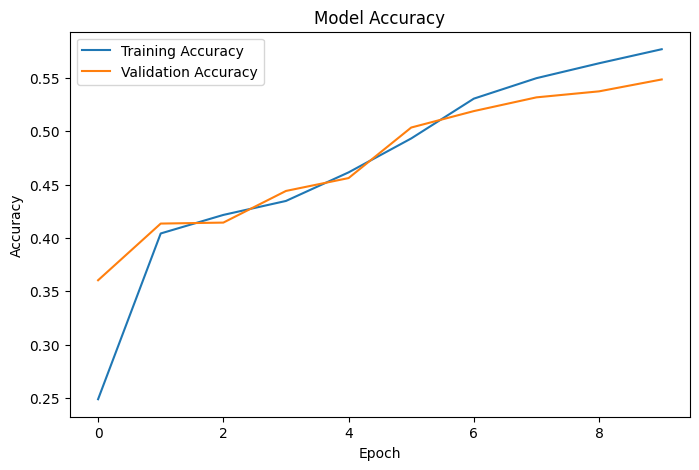

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Model Accuracy')
plt.legend()
plt.show()